In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dato.csv')

print(df.shape)
print(df.info())
print(df.head())
print(df.describe())

(7112, 10)
<class 'pandas.DataFrame'>
RangeIndex: 7112 entries, 0 to 7111
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Platform            7112 non-null   str  
 1   Genre               7112 non-null   str  
 2   Publisher           7112 non-null   str  
 3   NA_Sales            7112 non-null   str  
 4   EU_Sales            7112 non-null   str  
 5   JP_Sales            7112 non-null   str  
 6   Other_Sales         7112 non-null   str  
 7   Global_Sales        7112 non-null   str  
 8   Rating              7112 non-null   str  
 9   Critic_Score_Class  7112 non-null   str  
dtypes: str(10)
memory usage: 892.1 KB
None
  Platform     Genre Publisher NA_Sales EU_Sales JP_Sales Other_Sales  \
0      Wii    Sports  Nintendo    41,36    28,96     3,77        8,45   
1      Wii    Racing  Nintendo    15,68     12,8     3,79        3,29   
2      Wii    Sports  Nintendo    15,61    10,95     3,28        2

In [2]:
import pandas as pd

print(df.duplicated().sum())
df = df.drop_duplicates()

print(df.isnull().sum())
df = df.dropna(subset=['Publisher'])

cols_ventas = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
for col in cols_ventas:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')

24
Platform              0
Genre                 0
Publisher             0
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Rating                0
Critic_Score_Class    0
dtype: int64


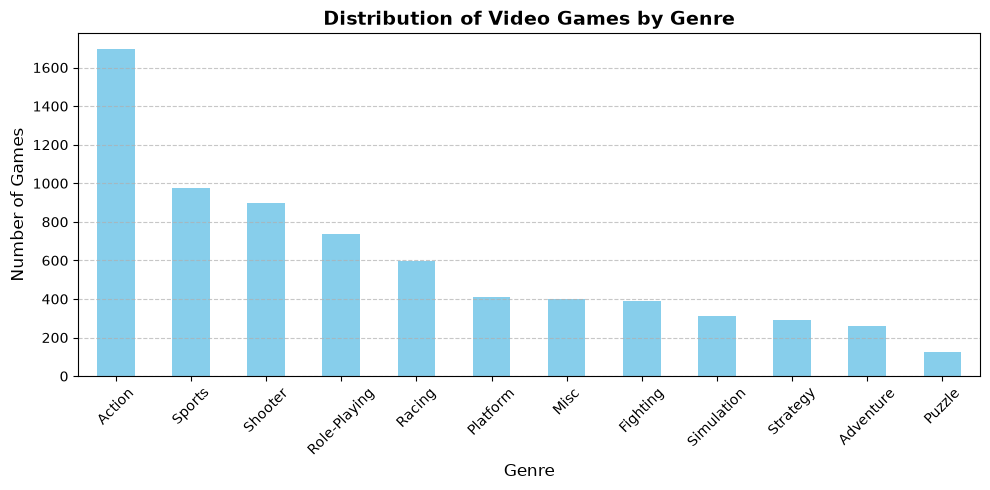

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
df['Genre'].value_counts().plot(kind='bar', color='skyblue')

plt.title('Distribution of Video Games by Genre', fontsize=14, fontweight='bold')
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Number of Games', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

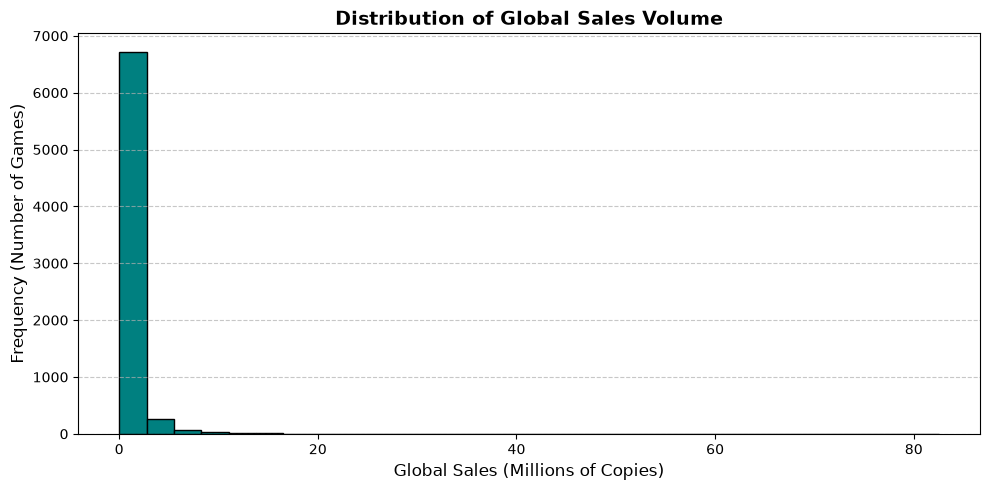

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(df['Global_Sales'], bins=30, color='teal', edgecolor='black')

plt.title('Distribution of Global Sales Volume', fontsize=14, fontweight='bold')
plt.xlabel('Global Sales (Millions of Copies)', fontsize=12)
plt.ylabel('Frequency (Number of Games)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

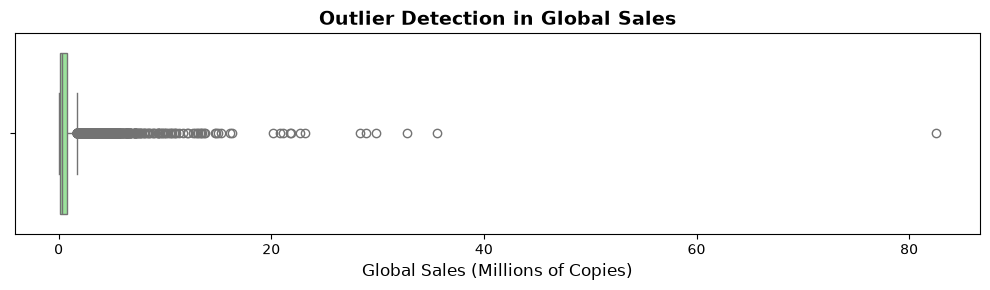

In [5]:
import seaborn as sns

plt.figure(figsize=(10, 3))
sns.boxplot(x=df['Global_Sales'], color='lightgreen')

plt.title('Outlier Detection in Global Sales', fontsize=14, fontweight='bold')
plt.xlabel('Global Sales (Millions of Copies)', fontsize=12)

plt.tight_layout()
plt.show()

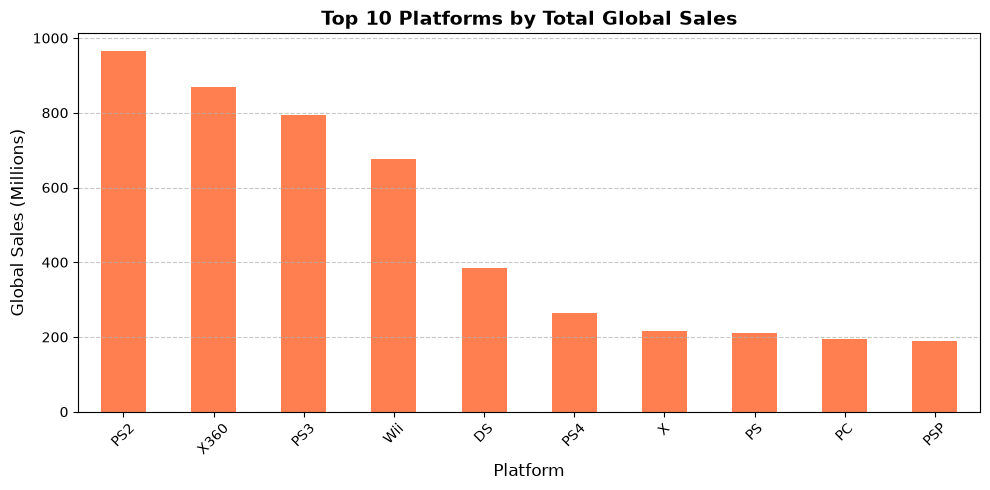

In [6]:
plt.figure(figsize=(10, 5))
platform_sales = df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False).head(10)
platform_sales.plot(kind='bar', color='coral')

plt.title('Top 10 Platforms by Total Global Sales', fontsize=14, fontweight='bold')
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Global Sales (Millions)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

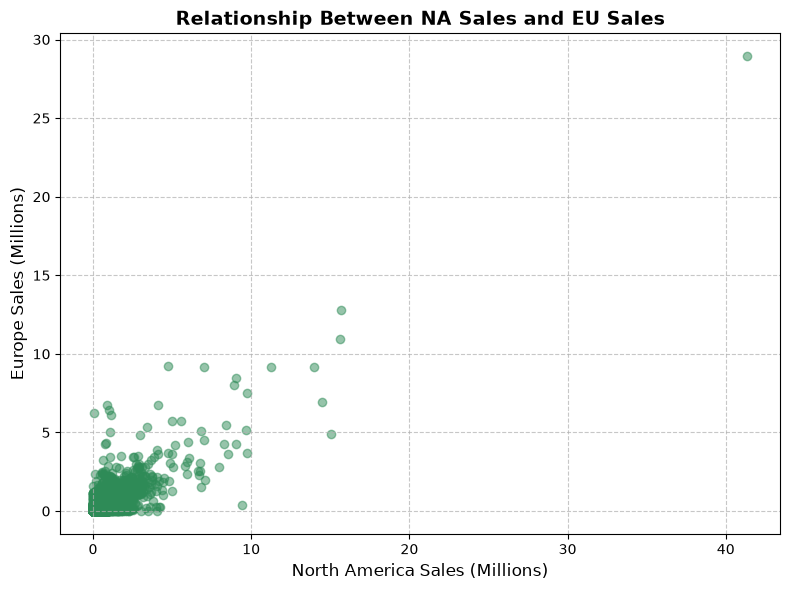

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(df['NA_Sales'], df['EU_Sales'], alpha=0.5, color='seagreen')

plt.title('Relationship Between NA Sales and EU Sales', fontsize=14, fontweight='bold')
plt.xlabel('North America Sales (Millions)', fontsize=12)
plt.ylabel('Europe Sales (Millions)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

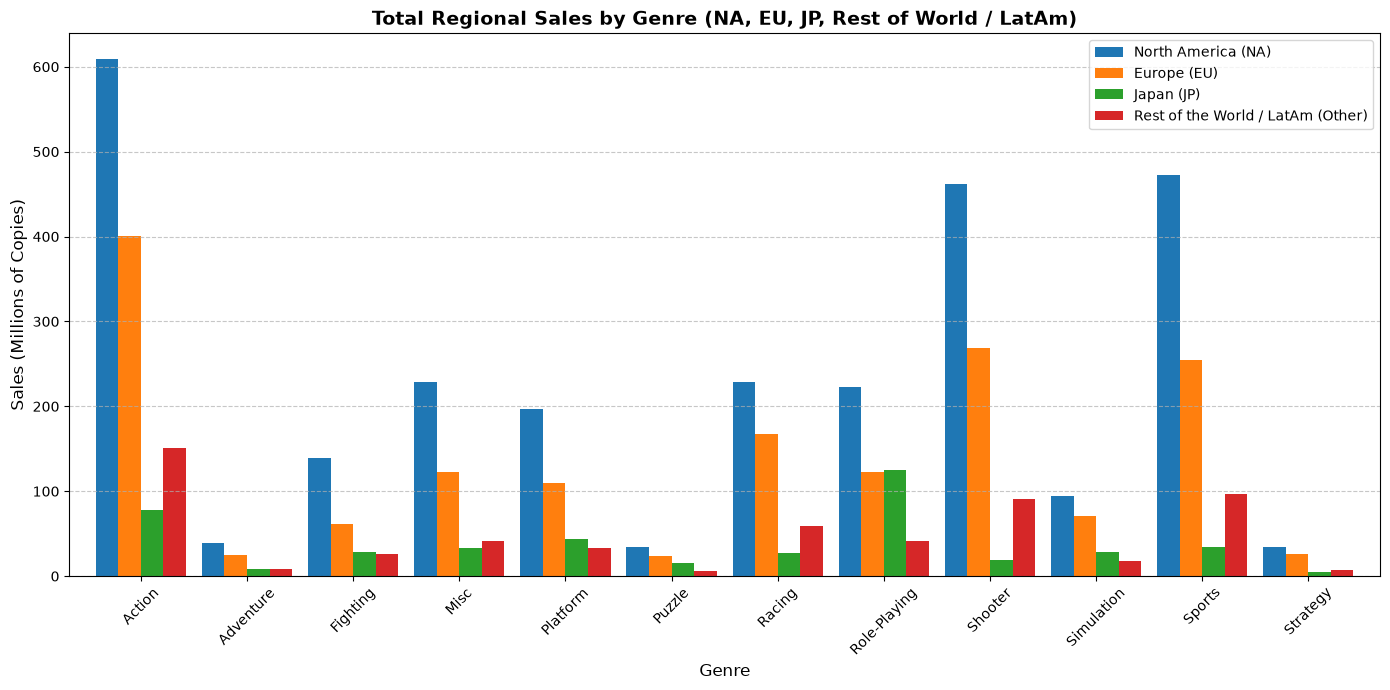

In [8]:
plt.figure(figsize=(14, 7))
genre_regional = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum()
genre_regional.plot(kind='bar', figsize=(14, 7), width=0.85)

plt.title('Total Regional Sales by Genre (NA, EU, JP, Rest of World / LatAm)', fontsize=14, fontweight='bold')
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Sales (Millions of Copies)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(['North America (NA)', 'Europe (EU)', 'Japan (JP)', 'Rest of the World / LatAm (Other)'])

plt.tight_layout()
plt.show()

In [9]:
df['NA_EU_Share'] = (df['NA_Sales'] + df['EU_Sales']) / df['Global_Sales']

df['Sales_Category'] = pd.qcut(
    df['Global_Sales'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Blockbuster']
)

print(df[['Global_Sales', 'NA_EU_Share', 'Sales_Category']].head())

   Global_Sales  NA_EU_Share Sales_Category
0         82.54     0.851951    Blockbuster
1         35.57     0.800675    Blockbuster
2         32.78     0.810250    Blockbuster
3         29.81     0.685340    Blockbuster
4         28.92     0.800138    Blockbuster


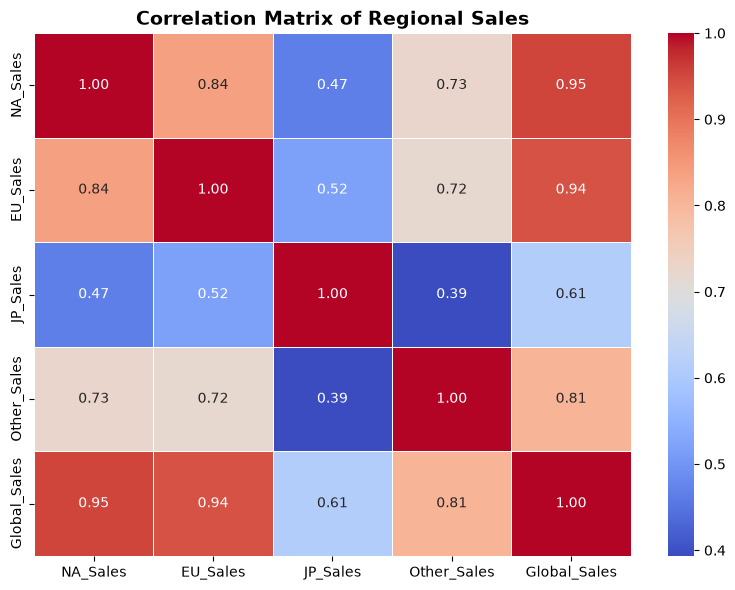

In [10]:
plt.figure(figsize=(8, 6))
correlation_matrix = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Matrix of Regional Sales', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\lorig\AppData\Local\Temp\ipykernel_10252\447327403.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Genre', y='Global_Sales', hue='Sales_Category', estimator=sum, ci=None)


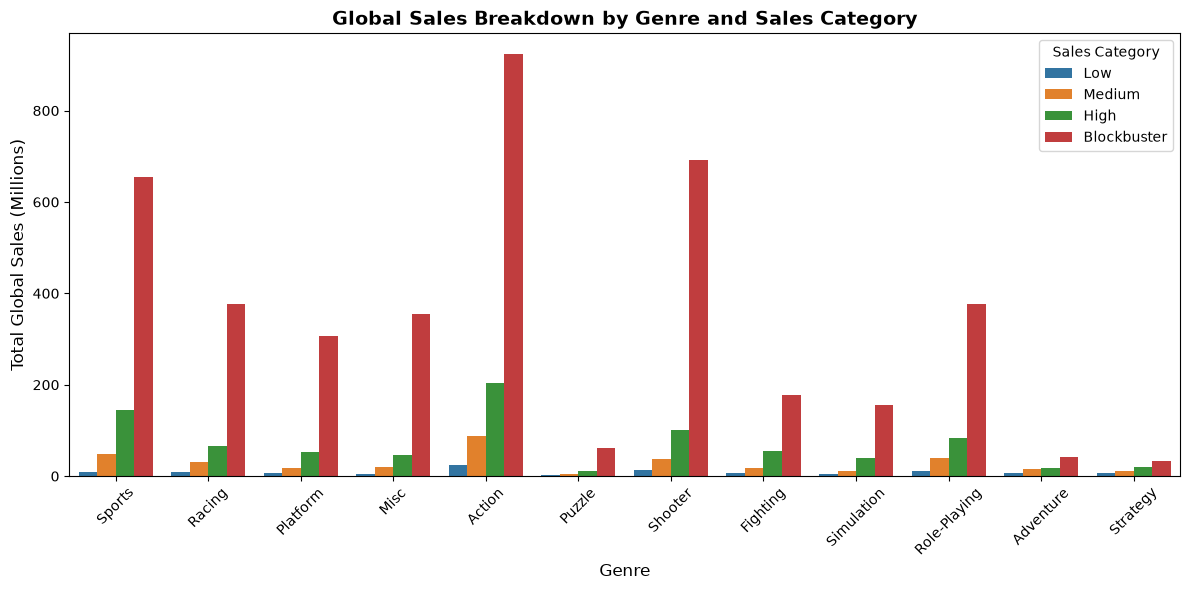

In [11]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Genre', y='Global_Sales', hue='Sales_Category', estimator=sum, ci=None)

plt.title('Global Sales Breakdown by Genre and Sales Category', fontsize=14, fontweight='bold')
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Total Global Sales (Millions)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Sales Category')

plt.tight_layout()
plt.show()

In [12]:
Q1 = df['Global_Sales'].quantile(0.25)
Q3 = df['Global_Sales'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

outliers = df[df['Global_Sales'] > upper_bound]
df_filtered = df[df['Global_Sales'] <= upper_bound]

print("Upper bound for normal sales:", upper_bound)
print("Number of outlier games:", len(outliers))
print("Number of standard games:", len(df_filtered))

Upper bound for normal sales: 1.71
Number of outlier games: 697
Number of standard games: 6391


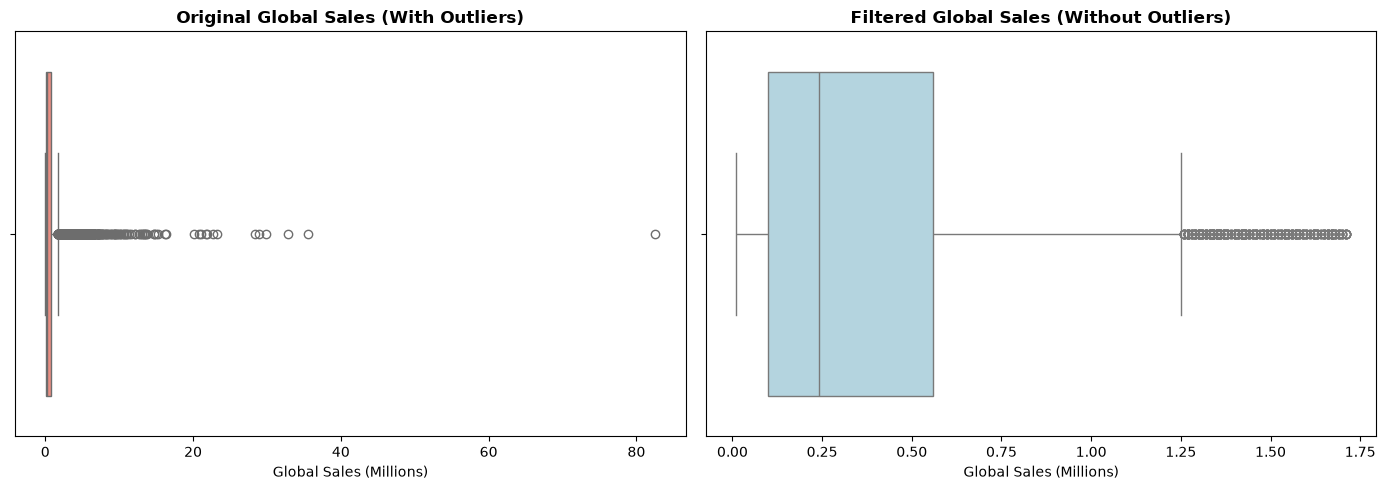

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(ax=axes[0], x=df['Global_Sales'], color='salmon')
axes[0].set_title('Original Global Sales (With Outliers)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Global Sales (Millions)')

sns.boxplot(ax=axes[1], x=df_filtered['Global_Sales'], color='lightblue')
axes[1].set_title('Filtered Global Sales (Without Outliers)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Global Sales (Millions)')

plt.tight_layout()
plt.show()

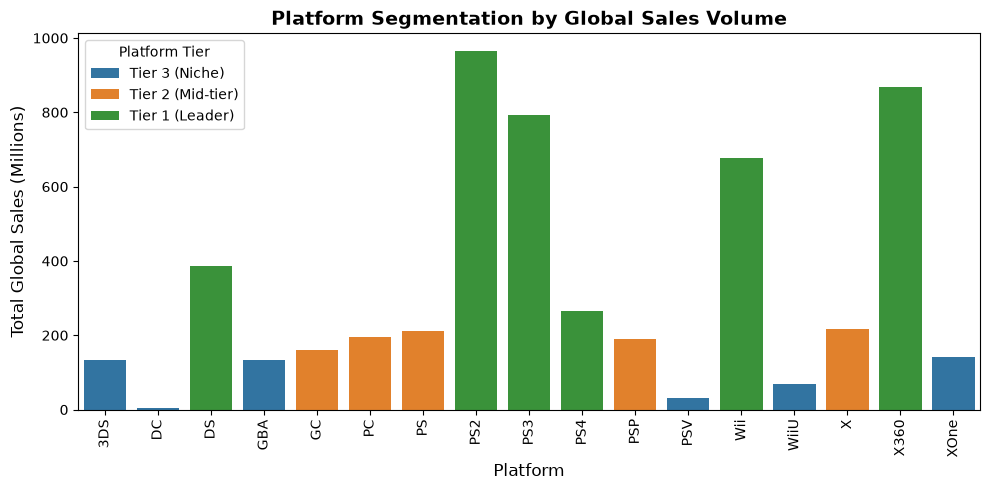

In [14]:
platform_totals = df.groupby('Platform')['Global_Sales'].sum().reset_index()

platform_totals['Platform_Tier'] = pd.qcut(
    platform_totals['Global_Sales'],
    q=3,
    labels=['Tier 3 (Niche)', 'Tier 2 (Mid-tier)', 'Tier 1 (Leader)']
)

plt.figure(figsize=(10, 5))
sns.barplot(data=platform_totals, x='Platform', y='Global_Sales', hue='Platform_Tier', dodge=False)

plt.title('Platform Segmentation by Global Sales Volume', fontsize=14, fontweight='bold')
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Total Global Sales (Millions)', fontsize=12)
plt.xticks(rotation=90)
plt.legend(title='Platform Tier')

plt.tight_layout()
plt.show()